In [12]:
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

EPILL = Path("../data/raw/epillid/ePillID_data")
OUT = Path("../data/processed")
train = pd.read_csv(OUT/"train.csv")
print(train.shape)
device = "cuda" if torch.cuda.is_available() else "cpu"

(188, 10)


In [13]:
from torchvision.models import mobilenet_v3_small , MobileNet_V3_Small_Weights

weights = MobileNet_V3_Small_Weights.DEFAULT
print(weights.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [14]:
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

row = train.iloc[0]
img = Image.open(EPILL / "classification_data" / row.image_path).convert("RGB")
print(img.size)


x = preprocess(img)
print(x.shape, x.dtype)

(224, 224)
torch.Size([3, 224, 224]) torch.float32


In [15]:
from torchvision.models import mobilenet_v3_small , MobileNet_V3_Small_Weights
import torch 

weights = MobileNet_V3_Small_Weights.DEFAULT

model = mobilenet_v3_small(weights=weights)
model.classifier = torch.nn.Identity()
model = model.to(device).eval()


with torch.no_grad():             #it means we are not training dont save in the memory 
    emb = model(x.unsqueeze(0).to(device))
print(emb.shape)


torch.Size([1, 576])


In [16]:
import torch 
import torch.nn.functional as F 

def embed_paths(paths,batch_size = 16):
    out = []
    
    for i in range(0, len(paths), batch_size):
        batch = [preprocess(Image.open(EPILL / "classification_data" / p).convert("RGB")) for p in paths[i:i + batch_size]]
        x = torch.stack(batch).to(device)

        with torch.no_grad():
            e = model(x)
            out.append(e.cpu())    # so that gpu memory get freed it moved to main memory 
    return torch.cat(out)



val = pd.read_csv(OUT / "val.csv")
ref = train[train.is_ref].reset_index(drop=True)

G = F.normalize(embed_paths(ref.image_path.tolist()), dim=1)
Q = F.normalize(embed_paths(val.image_path.tolist()), dim=1)
print(G.shape, Q.shape)


sim = Q @ G.T   #@-- matrix multiplicatio   n 
pills = sorted(ref.pilltype_id.unique())
pill_sim = torch.stack(
    [sim[:, torch.tensor((ref.pilltype_id == p).values)].max(dim=1).values for p in pills],
    dim=1)
true = torch.tensor([pills.index(p) for p in val.pilltype_id])
top5 = pill_sim.topk(5, dim=1).indices


top1_acc = (top5[:, 0] == true).float().mean().item()
top5_acc = (top5 == true[:, None]).any(dim=1).float().mean().item()
print(f"top-1: {top1_acc:.3f}   top-5: {top5_acc:.3f}")

torch.Size([80, 576]) torch.Size([40, 576])
top-1: 0.500   top-5: 0.825


20 photos wrong at top-1
13 of them still have the true pill in the top 5


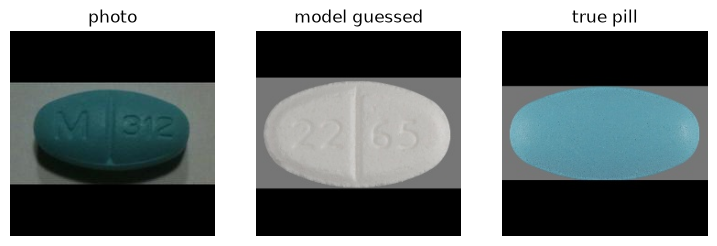

In [17]:
wrong = (top5[:, 0] != true).nonzero().flatten().tolist()
print(len(wrong), "photos wrong at top-1")
in_top5 = [i for i in wrong if (top5[i] == true[i]).any()]
print(len(in_top5), "of them still have the true pill in the top 5")






i = wrong[19]
q_path = val.image_path[i]
pred_pill = pills[top5[i, 0].item()]
true_pill = pills[true[i].item()]


pred_ref = ref[ref.pilltype_id == pred_pill].image_path.iloc[0]
true_ref = ref[ref.pilltype_id == true_pill].image_path.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, p, t in zip(axes, [q_path, pred_ref, true_ref], ["photo", "model guessed", "true pill"]):
    ax.imshow(Image.open(EPILL / "classification_data" / p))
    ax.set_title(t)
    ax.axis("off")
plt.show()

In [18]:
print(len(wrong))

20
